# Car-Hacking Dataset — Exploratory Data Analysis

Exploration of the **HCRL Car-Hacking Dataset** (Seo et al., 2018) after parsing
into the unified parquet schema (`python -m src.data.parser`).

Covered here:

1. Parsing summary (rows, injected ratios, detected timestamp gaps)
2. Class balance per attack file
3. Messages per CAN ID
4. Inter-arrival time distributions
5. Payload byte distributions
6. The timestamp gap in attack files — before/after trimming

All figures are saved to `reports/figures/`.

> **Limitation to keep in mind:** the vehicle was likely stationary during the
> attack captures, so the "normal" background traffic inside attack files
> differs from `normal_run_data.txt`, which was recorded while driving.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import (ATTACK_FILES, FIGURES_DIR, PROCESSED_DIR, RAW_DIR,
                        REPORTS_DIR, SEED)
from src.data.parser import detect_timestamp_gap

np.random.seed(SEED)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})

# Qualitative palette shared with the dashboard (one color per attack type)
COLORS = {"normal": "#8f96a3", "dos": "#7c5cd6", "fuzzy": "#2c9d94",
          "gear": "#d49020", "rpm": "#cc5495"}

with open(REPORTS_DIR / "parse_summary.json", encoding="utf-8") as f:
    parse_summary = json.load(f)
pd.DataFrame(parse_summary).T

,file,gap_seconds,rows_before_trim,rows_after_trim,rows_final,injected_rows,injected_ratio,duration_s,unique_ids,parse_seconds,malformed_lines
dos,DoS_dataset.csv,0.0,3665771,3665771,3665771,587521,0.1603,2832.7,27,35.2,NaN
fuzzy,Fuzzy_dataset.csv,2539.5,3838860,2947792,2947792,491847,0.1669,2466.0,2048,33.0,NaN
gear,gear_dataset.csv,5588.1,4443142,3552074,3552074,597252,0.1681,1949.2,26,27.9,NaN
rpm,RPM_dataset.csv,7744.9,4621702,3730634,3730634,654897,0.1755,1952.4,26,35.4,NaN
normal,normal_run_data.txt,0.0,988871,988871,988871,0,0.0,506.4,27,11.9,1


## 1. Load processed data

One parquet per source file, all in the unified schema.

In [2]:
SOURCES = ["normal", "dos", "fuzzy", "gear", "rpm"]
data = {name: pd.read_parquet(PROCESSED_DIR / f"{name}.parquet") for name in SOURCES}
for name, df in data.items():
    print(f"{name:>7}: {len(df):>9,} rows | {df['can_id'].nunique():>4} unique IDs "
          f"| {df['label'].mean():6.1%} injected "
          f"| {df['timestamp'].iloc[-1] - df['timestamp'].iloc[0]:7.0f} s")
data["dos"].head()

 normal:   988,871 rows |   27 unique IDs |   0.0% injected |     506 s
    dos: 3,665,771 rows |   27 unique IDs |  16.0% injected |    2833 s
  fuzzy: 2,947,792 rows | 2048 unique IDs |  16.7% injected |    2466 s
   gear: 3,552,074 rows |   26 unique IDs |  16.8% injected |    1949 s
    rpm: 3,730,634 rows |   26 unique IDs |  17.6% injected |    1952 s


,timestamp,can_id,dlc,byte0,byte1,byte2,byte3,byte4,byte5,byte6,byte7,label,attack_type,source
0,1.478198e+09,790,8,5,33,104,9,33,33,0,111,0,normal,dos
1,1.478198e+09,399,8,254,91,0,0,0,60,0,0,0,normal,dos
2,1.478198e+09,608,8,25,33,34,48,8,142,109,58,0,normal,dos
3,1.478198e+09,672,8,100,0,154,29,151,2,189,0,0,normal,dos
4,1.478198e+09,809,8,64,187,127,20,17,32,0,20,0,normal,dos


## 2. Class balance per attack file

Bars start at 0; counts are from the trimmed files actually used downstream.

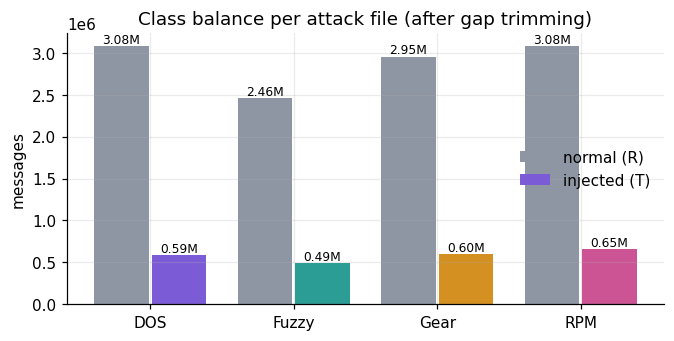

,normal,injected,injected_ratio
dos,3078250,587521,0.160272
fuzzy,2455945,491847,0.166853
gear,2954822,597252,0.168142
rpm,3075737,654897,0.175546


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
attacks = ["dos", "fuzzy", "gear", "rpm"]
normal_counts = [int((data[a]["label"] == 0).sum()) for a in attacks]
injected_counts = [int((data[a]["label"] == 1).sum()) for a in attacks]
x = np.arange(len(attacks))
ax.bar(x - 0.2, normal_counts, width=0.38, label="normal (R)", color=COLORS["normal"])
ax.bar(x + 0.2, injected_counts, width=0.38, label="injected (T)",
       color=[COLORS[a] for a in attacks])
for xi, (n, i) in zip(x, zip(normal_counts, injected_counts)):
    ax.text(xi - 0.2, n, f"{n/1e6:.2f}M", ha="center", va="bottom", fontsize=8)
    ax.text(xi + 0.2, i, f"{i/1e6:.2f}M", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [a.upper() if a in ("dos", "rpm") else a.capitalize() for a in attacks])
ax.set_ylabel("messages")
ax.set_title("Class balance per attack file (after gap trimming)")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_class_balance.png")
plt.show()

balance = pd.DataFrame({"normal": normal_counts, "injected": injected_counts}, index=attacks)
balance["injected_ratio"] = balance["injected"] / balance.sum(axis=1)
balance

## 3. Messages per CAN ID

Which identifiers dominate the bus. In the DoS capture the injected ID `0x000`
floods the bus (highest priority wins arbitration); spoofing attacks target
specific IDs (gear `0x043F`, RPM `0x0316`).

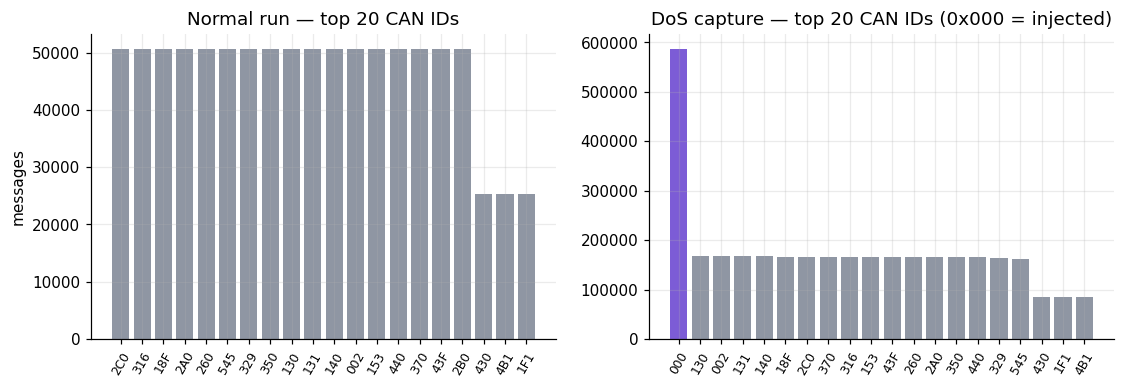

   dos:    1 distinct injected IDs | top: 0x000 (587,521)
 fuzzy: 2048 distinct injected IDs | top: 0x322 (294), 0x1E1 (293), 0x502 (293)
  gear:    1 distinct injected IDs | top: 0x43F (597,252)
   rpm:    1 distinct injected IDs | top: 0x316 (654,897)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

counts_normal = data["normal"]["can_id"].value_counts().head(20)
axes[0].bar([f"{i:03X}" for i in counts_normal.index], counts_normal.values,
            color=COLORS["normal"])
axes[0].set_title("Normal run — top 20 CAN IDs")
axes[0].set_ylabel("messages")
axes[0].tick_params(axis="x", rotation=60, labelsize=8)

counts_dos = data["dos"]["can_id"].value_counts().head(20)
bar_colors = [COLORS["dos"] if i == 0 else COLORS["normal"] for i in counts_dos.index]
axes[1].bar([f"{i:03X}" for i in counts_dos.index], counts_dos.values, color=bar_colors)
axes[1].set_title("DoS capture — top 20 CAN IDs (0x000 = injected)")
axes[1].tick_params(axis="x", rotation=60, labelsize=8)

fig.savefig(FIGURES_DIR / "eda_messages_per_id.png")
plt.show()

# Where do injections land, per attack?
for attack in ["dos", "fuzzy", "gear", "rpm"]:
    injected_ids = data[attack].loc[data[attack]["label"] == 1, "can_id"]
    top = injected_ids.value_counts().head(3)
    ids = ", ".join(f"0x{i:03X} ({c:,})" for i, c in top.items())
    print(f"{attack:>6}: {injected_ids.nunique():>4} distinct injected IDs | top: {ids}")

## 4. Inter-arrival time distributions

CAN traffic is highly periodic per ID. Globally the bus runs at ~0.2 ms per
message in every capture (left, log-log), so the global distribution alone is
a weak detector. The per-ID view (right) is the real signature: spoofed
frames on RPM ID `0x316` arrive far faster than the ID's legitimate ~10 ms
period.

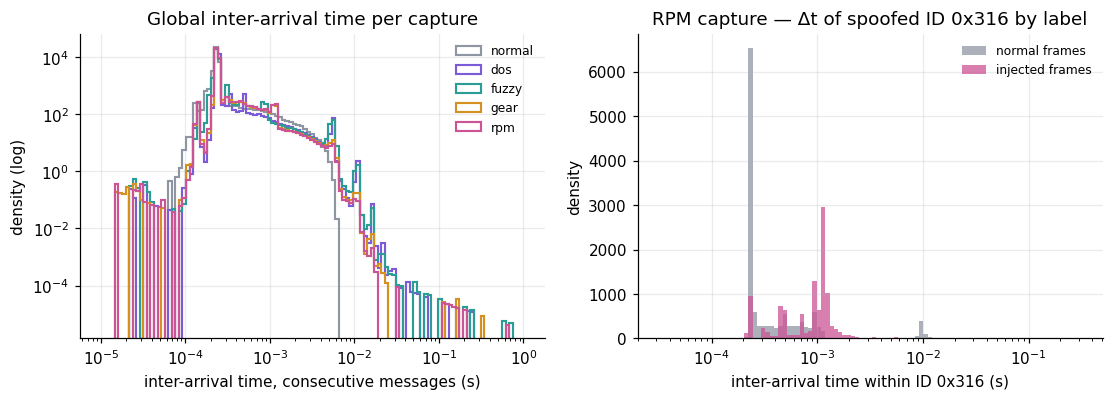

ID 0x2C0: median period 9.99 ms, std 0.32 ms  -> strongly periodic


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

bins = np.logspace(-5, 0, 120)
for name in SOURCES:
    dt = np.diff(data[name]["timestamp"].to_numpy())
    dt = dt[dt > 0]
    axes[0].hist(dt, bins=bins, histtype="step", density=True,
                 label=name, color=COLORS[name], linewidth=1.4)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("inter-arrival time, consecutive messages (s)")
axes[0].set_ylabel("density (log)")
axes[0].set_title("Global inter-arrival time per capture")
axes[0].legend(frameon=False, fontsize=8)

# Per-ID signature: Delta-t of RPM ID 0x316 in the RPM capture, by label
rpm = data["rpm"]
subset = rpm[rpm["can_id"] == 0x316].copy()
subset["dt"] = subset["timestamp"].diff()
bins_id = np.logspace(-4.5, -0.5, 100)
for label, name, color in [(0, "normal frames", COLORS["normal"]),
                           (1, "injected frames", COLORS["rpm"])]:
    dt = subset.loc[subset["label"] == label, "dt"].dropna()
    axes[1].hist(dt[dt > 0], bins=bins_id, density=True, alpha=0.75,
                 label=name, color=color)
axes[1].set_xscale("log")
axes[1].set_xlabel("inter-arrival time within ID 0x316 (s)")
axes[1].set_ylabel("density")
axes[1].set_title("RPM capture — Δt of spoofed ID 0x316 by label")
axes[1].legend(frameon=False, fontsize=8)

fig.savefig(FIGURES_DIR / "eda_interarrival.png")
plt.show()

# Per-ID periodicity example: a common ID in normal traffic
common_id = data["normal"]["can_id"].value_counts().index[0]
ts = data["normal"].loc[data["normal"]["can_id"] == common_id, "timestamp"].to_numpy()
print(f"ID 0x{common_id:03X}: median period {np.median(np.diff(ts))*1000:.2f} ms, "
      f"std {np.std(np.diff(ts))*1000:.2f} ms  -> strongly periodic")

## 5. Payload byte distributions

Fuzzing injects random payloads, flattening the byte-value distribution;
normal payloads are sparse (many constant/zero bytes).

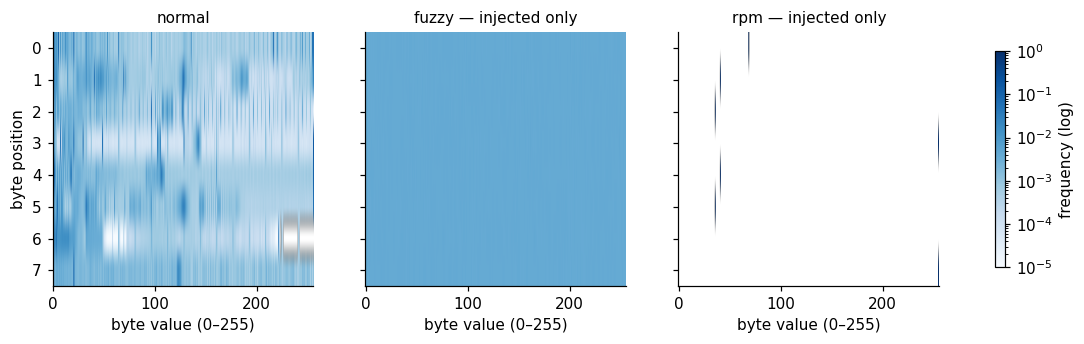

In [6]:
def byte_value_histogram(df: pd.DataFrame) -> np.ndarray:
    """Return an (8, 256) frequency matrix of payload byte values."""
    hist = np.zeros((8, 256))
    for i in range(8):
        hist[i] = np.bincount(df[f"byte{i}"].to_numpy(), minlength=256)
    return hist / hist.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.0), sharey=True)
panels = [("normal", data["normal"]),
          ("fuzzy — injected only", data["fuzzy"][data["fuzzy"]["label"] == 1]),
          ("rpm — injected only", data["rpm"][data["rpm"]["label"] == 1])]
for ax, (title, df) in zip(axes, panels):
    h = byte_value_histogram(df)
    im = ax.imshow(h, aspect="auto", cmap="Blues",
                   norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=1))
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("byte value (0–255)")
    ax.grid(False)
axes[0].set_ylabel("byte position")
fig.colorbar(im, ax=axes, shrink=0.85, label="frequency (log)")
fig.savefig(FIGURES_DIR / "eda_payload_bytes.png")
plt.show()

## 6. The timestamp gap — before/after trimming

The Fuzzy, gear and RPM files each contain one huge recording gap near their
end (an issue first documented by Verma et al. in the ROAD paper). Everything
after the gap is dropped by the parser; the plots show raw elapsed time vs row
index with the detected gap marked. The DoS file in this copy has **no** gap
above the 60 s threshold (largest: 22.4 s) and is kept whole.

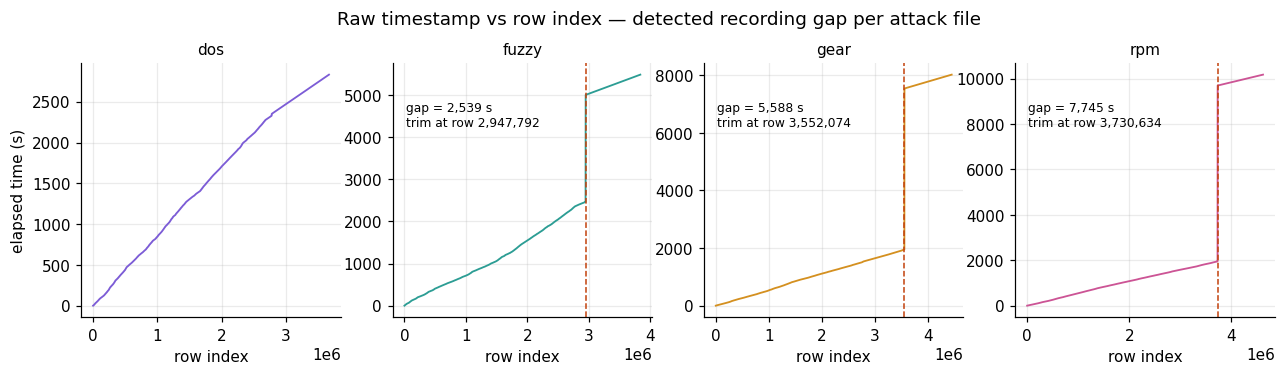

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.0), sharey=False)
for ax, (attack, filename) in zip(axes, ATTACK_FILES.items()):
    raw_ts = pd.read_csv(RAW_DIR / filename, header=None, usecols=[0],
                         names=["timestamp"], dtype={"timestamp": np.float64}
                         )["timestamp"].to_numpy()
    trim_index, gap_s = detect_timestamp_gap(raw_ts)
    elapsed = raw_ts - raw_ts[0]
    ax.plot(elapsed, color=COLORS[attack], linewidth=1.2)
    if trim_index is not None:
        ax.axvline(trim_index, color="#c2410c", linestyle="--", linewidth=1)
        ax.annotate(f"gap = {gap_s:,.0f} s\ntrim at row {trim_index:,}",
                    xy=(trim_index, elapsed[trim_index]),
                    xytext=(0.05, 0.75), textcoords="axes fraction", fontsize=8)
    ax.set_title(attack, fontsize=10)
    ax.set_xlabel("row index")
axes[0].set_ylabel("elapsed time (s)")
fig.suptitle("Raw timestamp vs row index — detected recording gap per attack file", y=1.04)
fig.savefig(FIGURES_DIR / "eda_timestamp_gap.png")
plt.show()

## Findings

- **Class balance** is attack-dependent: DoS/spoofing captures hold roughly
  13–17 % injected frames; they are *not* rare events at message level, but the
  anomaly detectors are still trained on normal traffic only.
- **DoS** floods ID `0x000` (highest arbitration priority); **gear/RPM
  spoofing** target a single legitimate ID each, while **fuzzy** sprays random
  IDs and payloads.
- **Inter-arrival times** are the strongest signal: normal per-ID traffic is
  strongly periodic, injections compress global inter-arrival times.
- **Payload bytes**: fuzzing flattens the byte-value distribution; normal
  payloads concentrate on a few values per byte position.
- **Timestamp gaps**: Fuzzy/gear/RPM contain one recording gap of 2539 s /
  5588 s / 7745 s each, detected and trimmed automatically; the trimmed
  captures span 2466 s / 1949 s / 1952 s — matching the durations reported by
  Verma et al. The DoS file has no gap > 60 s in this copy and is kept whole.
- **Domain-shift limitation**: attack captures were likely recorded with the
  car stationary, unlike the driving `normal_run_data.txt` — kept visible in
  the README and the dashboard.